# PFC worked example: latents, UMAP and predicted gene trajectories

This notebook loads the pre-trained PFC model (we pick seed 44 here), encodes every nucleus of
the human prefrontal cortex atlas (Herring et al., 2022; snRNA-seq and
snATAC-seq, six developmental stages) into the shared latent space, and then:

1. **Block 1** draws one UMAP of both modalities in that latent space, as in
   panel (b) of the paper's PFC figure;
2. **Block 2** transports Gestation astrocytes through the fitted latent SDE to
   every later stage, decodes them as RNA expression, and compares the
   predicted maturation of eight marker genes with a control cohort and with
   the observed expression, as in panel (e). Only the training split is used.

**Inputs.** Dataset and pretrained model can be found from the Figshare files

> On some machines one may need to import `umap` before `torch` (i.e. before `mtvae`);
>  otherwise the session can crash due tp duplicate OpenMP runtime.

In [1]:
import os
import warnings
from collections import OrderedDict

import umap  # before torch, see the note above
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mtvae
from mtvae import astro
from mtvae._constants import STAGES_ORDERED

warnings.filterwarnings("ignore", category=UserWarning)
DATA = mtvae.data_root(os.environ.get("MTVAE_DATA", "path/to/figshare"))
SEED = 44

## Load the model, encode, and draw the latent UMAP

`load_example` returns the two modalities as the model saw them in training
(RNA input unclipped, ATAC clipped at ±10), with the whole-donor training mask
attached. `load_model` rebuilds the co-adapted encoder, both decoders and the
SDE from `models/pfc_full/s44/`.

In [ ]:
data = mtvae.load_example("pfc", DATA)
model = mtvae.load_model(mtvae.model_dir("pfc", SEED, DATA))
for m in data.modalities:
    print(f"{m.name:5s} {m.x.shape[0]:7,d} nuclei x {m.x.shape[1]:,d} features, "
          f"{int(m.train.sum()):,d} in the training split")
print("stages:", list(data.stages))

rna   154,748 nuclei x 5,000 features, 117,932 in the training split
atac   87,339 nuclei x 5,000 features, 64,011 in the training split
stages: ['Gestation', 'Neonatal', 'Infancy', 'Childhood', 'Adolescence', 'Adulthood']


In [ ]:
z = model.encode(data)                        # posterior means, every nucleus
for m, zm in z.items():
    shipped = np.load(DATA / f"models/pfc_full/s{SEED}/latents/z_coadapt_{m}.npy")
    print(f"{m:5s} latent {zm.shape}; max |difference| from the released latent "
          f"{np.abs(zm - shipped).max():.1e}")

rna   latent (154748, 50); max |difference| from the released latent 6.0e-06
atac  latent (87339, 50); max |difference| from the released latent 5.7e-06


Doublecheck if the outputs agree with the figshare record.

We visualise a subset of 20,000 annotated nuclei per modality for sake of efficiency 


In [ ]:
meta = {m: pd.read_csv(DATA / f"data/pfc/{m}_metadata.csv") for m in ("rna", "atac")}
TYPES = ["PN_dev", "MGE_dev", "L2-3", "L4", "L5-6", "SST", "VIP", "PV",
         "ID2", "OPC", "Oligo", "Astro", "Micro"]
palette = {t: plt.get_cmap("tab20")(i) for i, t in enumerate(TYPES)}

def draw(labels, n, seed):
    keep = np.where(labels != "Other")[0]
    return np.sort(np.random.default_rng(seed).choice(keep, n, replace=False))

idx = {"rna": draw(meta["rna"]["coarse_type"].values, 20_000, 0),
       "atac": draw(meta["atac"]["coarse_type"].values, 20_000, 1)}
X = np.concatenate([z["rna"][idx["rna"]], z["atac"][idx["atac"]]])
cell_type = np.concatenate([meta[m]["coarse_type"].values[idx[m]] for m in ("rna", "atac")])
modality = np.array(["RNA"] * 20_000 + ["ATAC"] * 20_000)
emb = umap.UMAP(n_neighbors=30, min_dist=0.3, metric="euclidean",
                random_state=0).fit_transform(X)

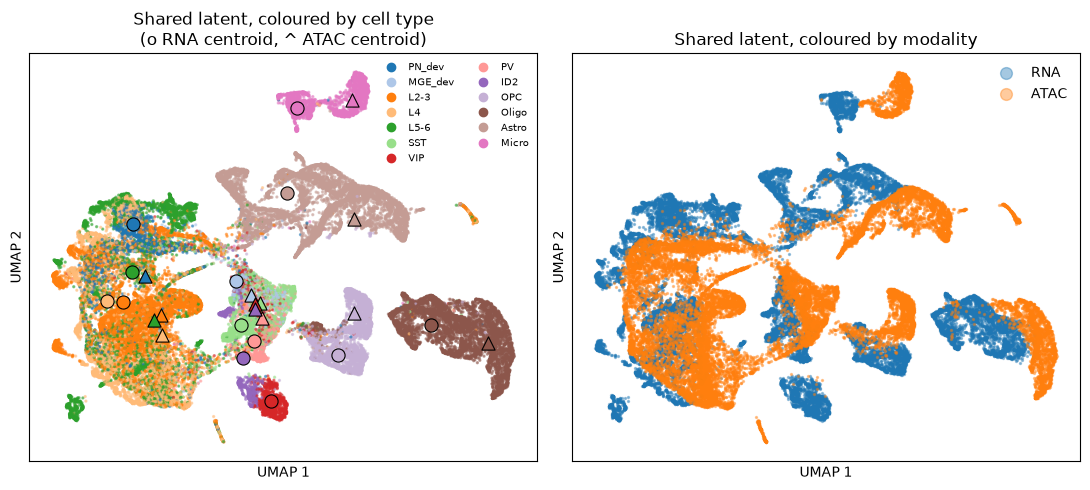

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
order = np.random.default_rng(0).permutation(len(emb))      # no modality drawn on top
axes[0].scatter(*emb[order].T, s=2, alpha=0.5, c=[palette[t] for t in cell_type[order]])
for t in TYPES:                                              # per-modality type centroids
    for mod, mk in (("RNA", "o"), ("ATAC", "^")):
        sel = (cell_type == t) & (modality == mod)
        if sel.sum() >= 5:
            axes[0].scatter(*emb[sel].mean(0), marker=mk, s=90, color=palette[t],
                            edgecolors="k", linewidths=0.8)
axes[0].legend(handles=[plt.Line2D([], [], ls="", marker="o", color=palette[t], label=t)
                        for t in TYPES], fontsize=7, ncol=2, frameon=False, loc="best")
axes[0].set_title("Shared latent, coloured by cell type\n(o RNA centroid, ^ ATAC centroid)")
for mod, col in (("RNA", "tab:blue"), ("ATAC", "tab:orange")):
    sel = modality[order] == mod
    axes[1].scatter(*emb[order][sel].T, s=2, alpha=0.4, color=col, label=mod)
axes[1].legend(markerscale=6, frameon=False)
axes[1].set_title("Shared latent, coloured by modality")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
plt.tight_layout()

## Predicted astrocyte maturation (training split ver.)

We follow procedure described in the paper. 

* **Cohorts.** At Gestation,draw 300 astrocytes
  and then 100 non-astrocytes (control).
* **Transport.** Each nucleus starts from its own modality's latent. The latents are then propogated to every stage through the common SDE.
* **Readout.** Decode every stage with the RNA decoder, so each trajectory is
  read as RNA expression regardless of the modality it was from. We report average over all samples.

In [6]:
coarse = {m: meta[m]["coarse_type"].values for m in meta}
stage = {m: mtvae.io.stage_index(meta[m]["stage_id"], STAGES_ORDERED) for m in meta}
train = {m.name: m.train for m in data.modalities}

mixed = astro.cohort_trajectories(
    model, z, astro.gestation_pools(coarse, stage, train, modalities=("rna", "atac")))
rna_only = astro.cohort_trajectories(
    model, z, astro.gestation_pools(coarse, stage, train, modalities=("rna",)))
print("astrocyte cohort (mixed):", mixed["composition"])
print("control cohort (RNA only):", rna_only["composition"])

genes = [g.strip() for g in open(DATA / "data/pfc/rna_hvg_list.txt") if g.strip()]
gi = {g: genes.index(g) for g in astro.IMMATURE_GENES + astro.MATURE_GENES}
x_rna = data["rna"].x                                   # the RNA input (z-scored HVGs)
is_astro = coarse["rna"] == "Astro"
observed = {g: np.array([x_rna[(stage["rna"] == s) & is_astro, gi[g]].mean()
                         for s in range(len(STAGES_ORDERED))]) for g in gi}

astrocyte cohort (mixed): {'cognate_rna': 254, 'cognate_atac': 46, 'control_rna': 80, 'control_atac': 20}
control cohort (RNA only): {'cognate_rna': 300, 'control_rna': 100}


rising margin per mature gene: {'NDRG2': 1.1911, 'FGFR3': 0.8627, 'ALDH1A1': 1.3416, 'SLC1A2': 0.6741}
mean rising margin: 1.0174


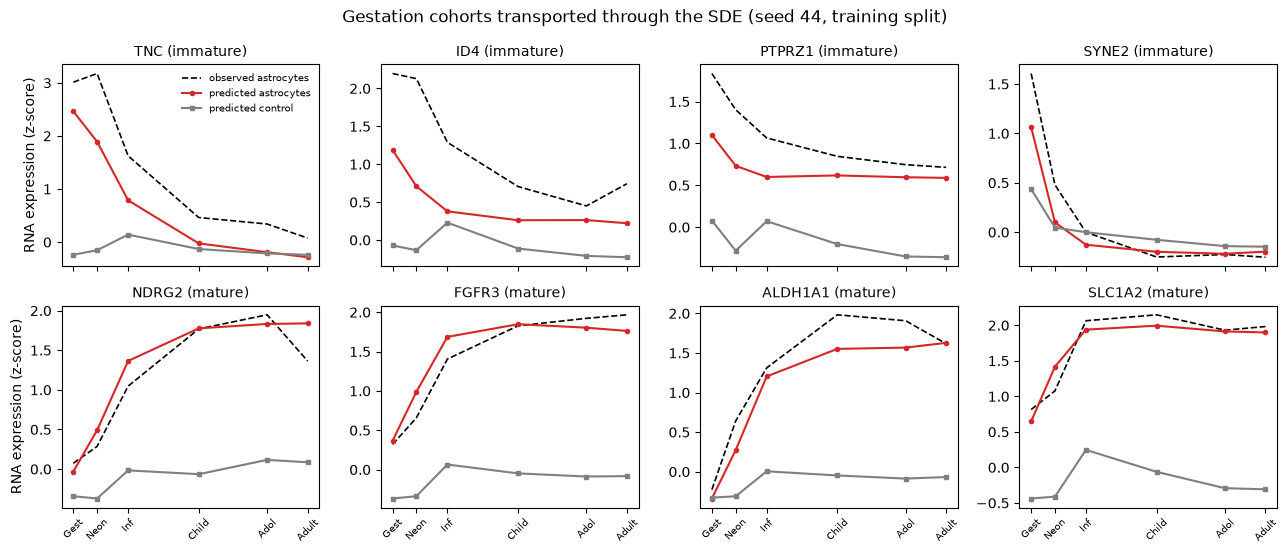

In [7]:
abbr = ["Gest", "Neon", "Inf", "Child", "Adol", "Adult"]
t = model.stage_times
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharex=True)
for ax, g in zip(axes.ravel(), astro.IMMATURE_GENES + astro.MATURE_GENES):
    ax.plot(t, observed[g], "k--", lw=1.2, label="observed astrocytes")
    ax.plot(t, mixed["cognate"][:, gi[g]], "-o", color="tab:red", ms=3,
            label="predicted astrocytes")
    ax.plot(t, rna_only["control"][:, gi[g]], "-s", color="tab:gray", ms=3,
            label="predicted control")
    kind = "mature" if g in astro.MATURE_GENES else "immature"
    ax.set_title(f"{g} ({kind})", fontsize=10)
    ax.set_xticks(t); ax.set_xticklabels(abbr, fontsize=7, rotation=45)
axes[0, 0].legend(fontsize=7, frameon=False)
for ax in axes[:, 0]:
    ax.set_ylabel("RNA expression (z-score)")
fig.suptitle(f"Gestation cohorts transported through the SDE (seed {SEED}, training split)")
plt.tight_layout()

tool = lambda c: c[3:5].mean(0) - c[0:2].mean(0)
margin = {g: tool(mixed["cognate"][:, gi[g]]) - tool(rna_only["control"][:, gi[g]])
          for g in astro.MATURE_GENES}
print("rising margin per mature gene:", {g: round(float(v), 4) for g, v in margin.items()})
print(f"mean rising margin: {np.mean(list(margin.values())):.4f}")